# Linesearch Implicit NN From Spring Data

This notebook generates target geometries with `SpringFF`, then trains `NNPotentialFF` with `LinesearchImplicitMultipleSystemOptimizer`. This optimizer avoids exact line minimization, which can be awkward for neural-network potentials.


In [8]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchDirectionalImplicitMultipleSystemOptimizer as LinesearchImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param
from geomatry.ff.NN import NNPotentialFF


In [9]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [10]:
systemN = 40
N = 8
N_pairs = 12
max_Za = 1
fixed_atom_indices = [0,1,2]

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)

target_ff = SpringFF(max_Za)
target_ff.reset_parameters(k, r0)
params_star = copy.deepcopy(target_ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target k', k[1:, 1:].mean().item())
print('sample target r0', r0[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target k 1.1668302430119752
sample target r0 0.7102299621523578
sample min distances [0.28235798766249653, 0.9442861238507423, 0.9838033829332286]


In [11]:
# Use SpringFF only to generate target optimized geometries.
target_optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, target_ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
Ra_star_list = target_optimizer.Ra_stars

from geomatry.opt_Energy_approximated.calculator import get_ase_atoms

with torch.no_grad():
    target_energies = torch.stack([
        target_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

# Train the NN force field with Linesearch implicit gradients.
nn_ff = NNPotentialFF(max_Za, hidden_dim=24)
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
params_0 = copy.deepcopy(nn_ff.state_dict())

print('target geometries', len(Ra_star_list))
print('NN parameter tensors', len(params_0))


target geometries 40
NN parameter tensors 18


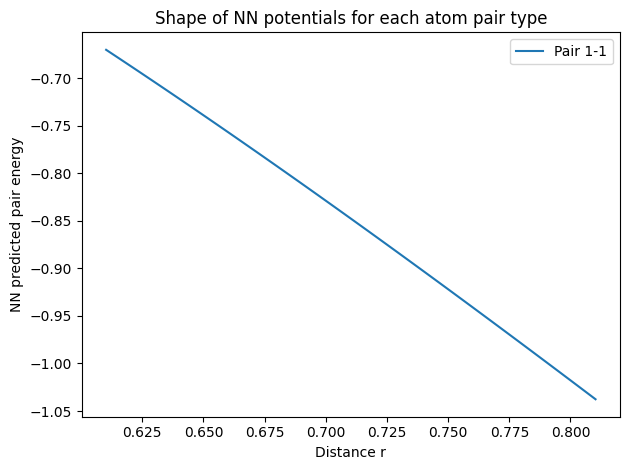

In [12]:

r_vals = torch.linspace(r0[1:, 1:].mean().item()-0.1, r0[1:, 1:].mean().item()+0.1, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()



  0%|          | 0/801 [00:01<?, ?it/s, alpha_star=-7.4492e-01, min_epsilon=N/A, total_scale=1.252722e-01]

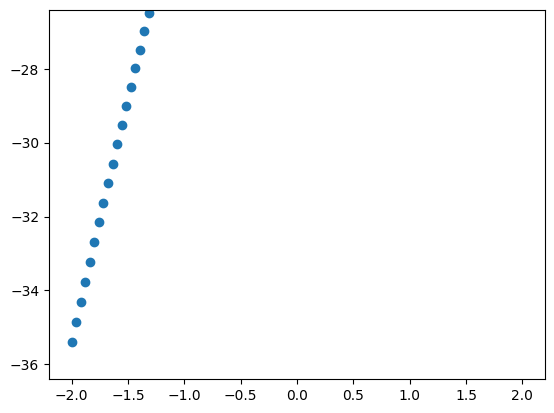

  0%|          | 1/801 [00:01<19:32,  1.47s/it, alpha_star=-7.4492e-01, min_epsilon=N/A, total_scale=1.252722e-01]

-0.7449159372347516
Iteration 0, alpha_star=-7.4492e-01, total_scale=1.252722e-01


 10%|▉         | 80/801 [01:25<11:02,  1.09it/s, alpha_star=-5.0584e-02, min_epsilon=N/A, total_scale=3.286625e-02]

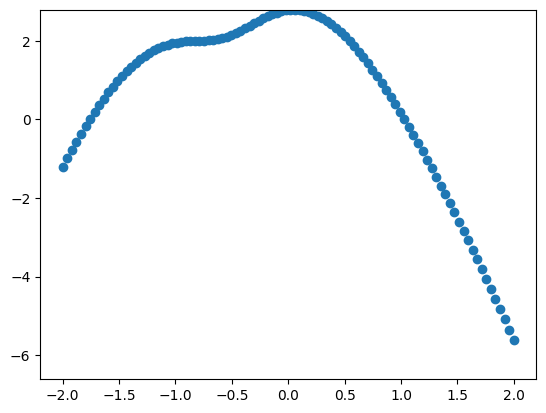

 10%|█         | 81/801 [01:26<11:13,  1.07it/s, alpha_star=-5.0584e-02, min_epsilon=N/A, total_scale=3.286625e-02]

-0.05058386352182873
Iteration 80, alpha_star=-5.0584e-02, total_scale=3.286625e-02


 20%|█▉        | 160/801 [02:33<10:46,  1.01s/it, alpha_star=-6.4148e-02, min_epsilon=N/A, total_scale=4.664333e-02]

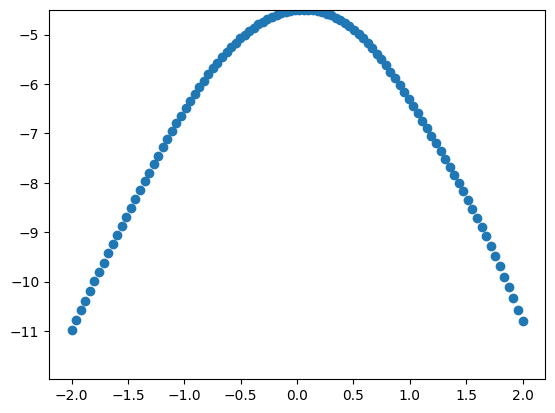

 20%|██        | 161/801 [02:33<12:05,  1.13s/it, alpha_star=-6.4148e-02, min_epsilon=N/A, total_scale=4.664333e-02]

-0.06414776017819783
Iteration 160, alpha_star=-6.4148e-02, total_scale=4.664333e-02


 30%|██▉       | 240/801 [03:55<09:47,  1.05s/it, alpha_star=-3.8648e-02, min_epsilon=N/A, total_scale=1.937540e-02]

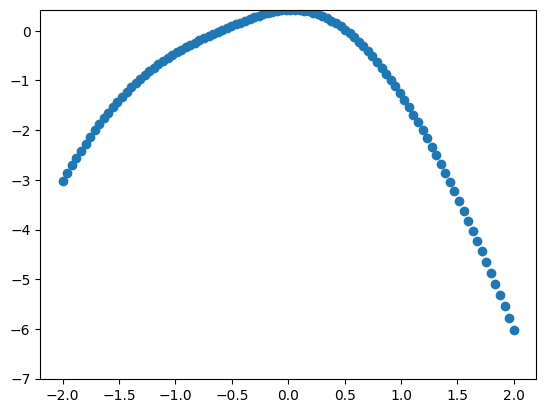

 30%|███       | 241/801 [03:55<10:29,  1.12s/it, alpha_star=-3.8648e-02, min_epsilon=N/A, total_scale=1.937540e-02]

-0.03864804489898865
Iteration 240, alpha_star=-3.8648e-02, total_scale=1.937540e-02


 40%|███▉      | 320/801 [05:15<10:10,  1.27s/it, alpha_star=-2.7612e-02, min_epsilon=N/A, total_scale=1.380355e-02]

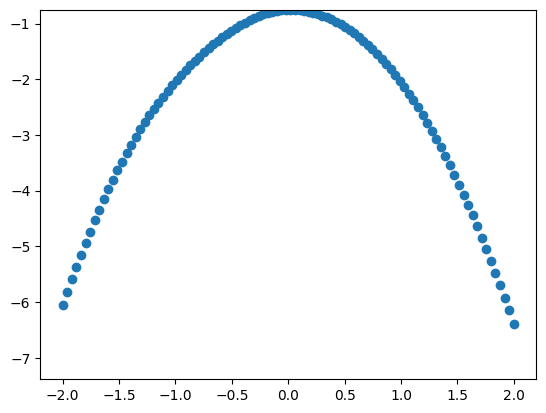

 40%|████      | 321/801 [05:15<10:59,  1.37s/it, alpha_star=-2.7612e-02, min_epsilon=N/A, total_scale=1.380355e-02]

-0.027612324622405676
Iteration 320, alpha_star=-2.7612e-02, total_scale=1.380355e-02


 50%|████▉     | 400/801 [06:34<04:40,  1.43it/s, alpha_star=-1.3372e-01, min_epsilon=N/A, total_scale=3.464998e-02]

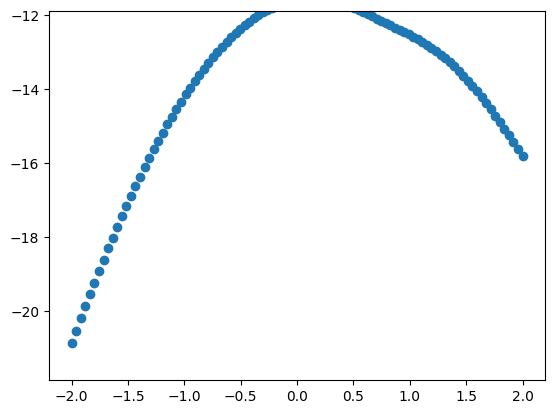

 50%|█████     | 401/801 [06:35<05:11,  1.28it/s, alpha_star=-1.3372e-01, min_epsilon=N/A, total_scale=3.464998e-02]

-0.1337173960699255
Iteration 400, alpha_star=-1.3372e-01, total_scale=3.464998e-02


 60%|█████▉    | 480/801 [07:43<04:22,  1.22it/s, alpha_star=-1.5799e-02, min_epsilon=N/A, total_scale=1.027039e-02]

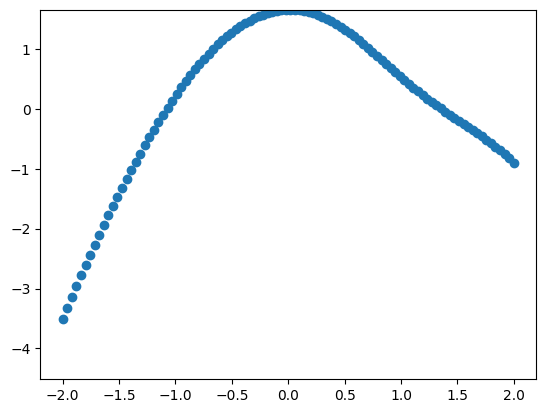

 60%|██████    | 481/801 [07:44<05:01,  1.06it/s, alpha_star=-1.5799e-02, min_epsilon=N/A, total_scale=1.027039e-02]

-0.01579915139871959
Iteration 480, alpha_star=-1.5799e-02, total_scale=1.027039e-02


 70%|██████▉   | 560/801 [08:44<02:55,  1.38it/s, alpha_star=-6.4459e-03, min_epsilon=N/A, total_scale=5.052246e-03]

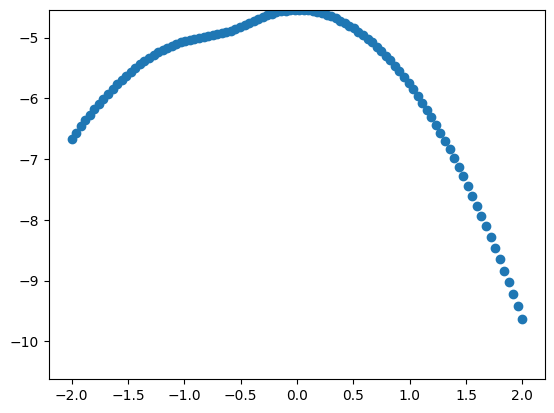

 70%|███████   | 561/801 [08:44<03:15,  1.23it/s, alpha_star=-6.4459e-03, min_epsilon=N/A, total_scale=5.052246e-03]

-0.006445875258802632
Iteration 560, alpha_star=-6.4459e-03, total_scale=5.052246e-03


 80%|███████▉  | 640/801 [09:44<02:07,  1.27it/s, alpha_star=-7.2979e-03, min_epsilon=N/A, total_scale=5.878982e-03]

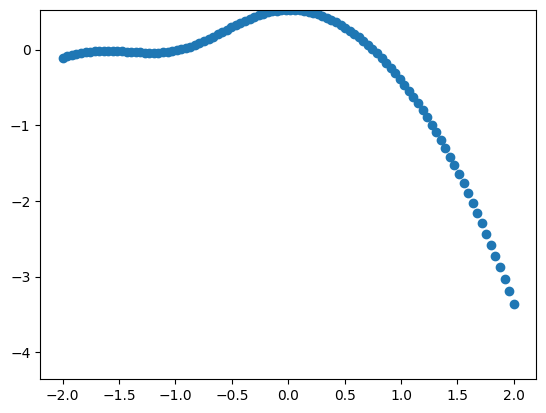

 80%|████████  | 641/801 [09:44<02:12,  1.21it/s, alpha_star=-7.2979e-03, min_epsilon=N/A, total_scale=5.878982e-03]

-0.007297923281307371
Iteration 640, alpha_star=-7.2979e-03, total_scale=5.878982e-03


 90%|████████▉ | 720/801 [10:52<01:11,  1.14it/s, alpha_star=-1.1253e-02, min_epsilon=N/A, total_scale=8.077017e-03]

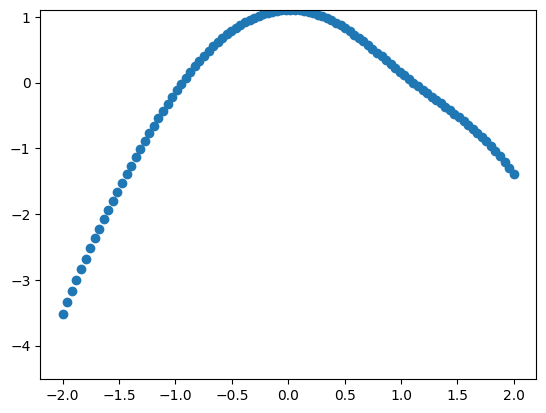

 90%|█████████ | 721/801 [10:52<01:12,  1.10it/s, alpha_star=-1.1253e-02, min_epsilon=N/A, total_scale=8.077017e-03]

-0.011253080972567829
Iteration 720, alpha_star=-1.1253e-02, total_scale=8.077017e-03


100%|█████████▉| 800/801 [11:54<00:00,  1.33it/s, alpha_star=-1.6159e-03, min_epsilon=N/A, total_scale=5.336565e-03]

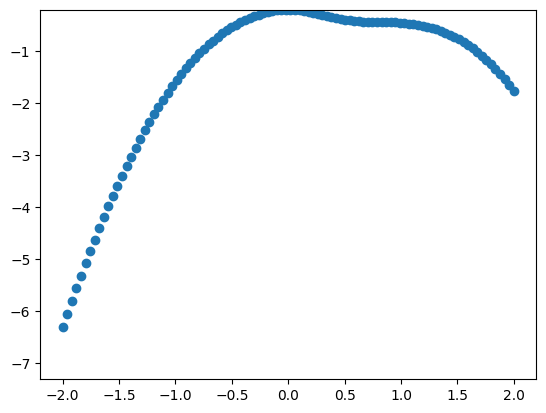

100%|██████████| 801/801 [11:54<00:00,  1.12it/s, alpha_star=-1.6159e-03, min_epsilon=N/A, total_scale=5.336565e-03]


-0.0016158771368504903
Iteration 800, alpha_star=-1.6159e-03, total_scale=5.336565e-03
optimization complete


In [13]:
params_0 = copy.deepcopy(nn_ff.state_dict())
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=801, print_period=80, e_size=0.2, eN=9, sg=2)
print('optimization complete')


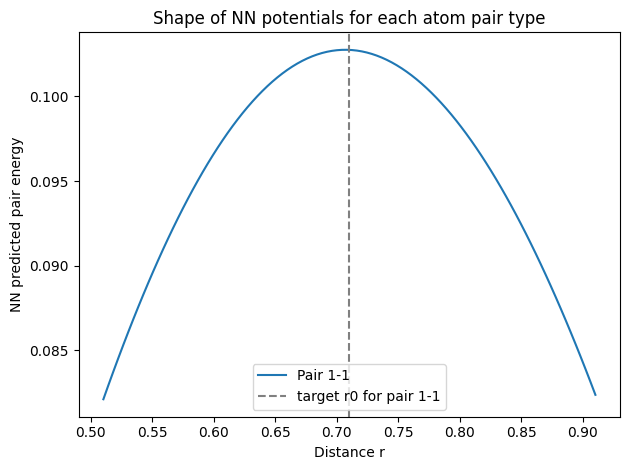

In [14]:
nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(r0[1:, 1:].mean().item()-0.2, r0[1:, 1:].mean().item()+0.2, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.axvline(r0[i, j].item(), color='gray', linestyle='--', label=f'target r0 for pair {i}-{j}')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()
